In [1]:
from LunaTrace import *
import matplotlib.pyplot as plt

In [2]:
df = makeDF("2026-11-11T12:00:00Z", "2027-11-11T12:00:00Z")

In [3]:
lat, long = -89.67, 129.78
_, _, elev, slope = getMoonState(lat, long)
df = calcRVect(lat, long, df)

In [4]:
Spts = df[['SX', 'SY', 'SZ']].to_numpy()
Epts = df[['EX', 'EY', 'EZ']].to_numpy()

df['SCritTheta'] = getCritAngle(-89.67, 129.78, Spts, elevation_grid, dem_transform)
df['ECritTheta'] = getCritAngle(-89.67, 129.78, Epts, elevation_grid, dem_transform)

In [5]:
df.head()

,datetime_utc,iso_utc_str,et,SX,SY,SZ,EX,EY,EZ,PSX,PSY,PSZ,PEX,PEY,PEZ,STheta,ETheta,SCritTheta,ECritTheta
0,2026-11-11 12:00:00+00:00,2026-11-11T12:00:00Z,8.476705e+08,-1.360644e+08,5.746467e+07,-4.002919e+06,400647.517211,13681.071816,43870.327055,-1.360643e+08,5.746466e+07,-4.001185e+06,400653.909603,13673.393981,45604.909304,1.844920,-6.692372,20.098165,21.737097
1,2026-11-11 14:00:00+00:00,2026-11-11T14:00:00Z,8.476777e+08,-1.350231e+08,5.986955e+07,-4.003709e+06,400853.859612,13033.402988,43631.219868,-1.350230e+08,5.986954e+07,-4.001974e+06,400860.252004,13025.725153,45365.802117,1.847872,-6.656110,20.040541,21.734853
2,2026-11-11 16:00:00+00:00,2026-11-11T16:00:00Z,8.476849e+08,-1.339394e+08,6.225556e+07,-4.004473e+06,401056.059090,12377.555740,43378.215698,-1.339394e+08,6.225555e+07,-4.002738e+06,401062.451482,12369.877905,45112.797946,1.850719,-6.617975,20.006985,21.732634
3,2026-11-11 18:00:00+00:00,2026-11-11T18:00:00Z,8.476921e+08,-1.328136e+08,6.462196e+07,-4.005211e+06,401253.927147,11713.636907,43111.411085,-1.328136e+08,6.462195e+07,-4.003477e+06,401260.319539,11705.959072,44845.993334,1.853462,-6.577982,20.018798,21.720717
4,2026-11-11 20:00:00+00:00,2026-11-11T20:00:00Z,8.476993e+08,-1.316462e+08,6.696800e+07,-4.005925e+06,401447.273783,11041.760716,42830.906283,-1.316462e+08,6.696800e+07,-4.004190e+06,401453.666175,11034.082880,44565.488532,1.856099,-6.536148,19.999375,21.717982


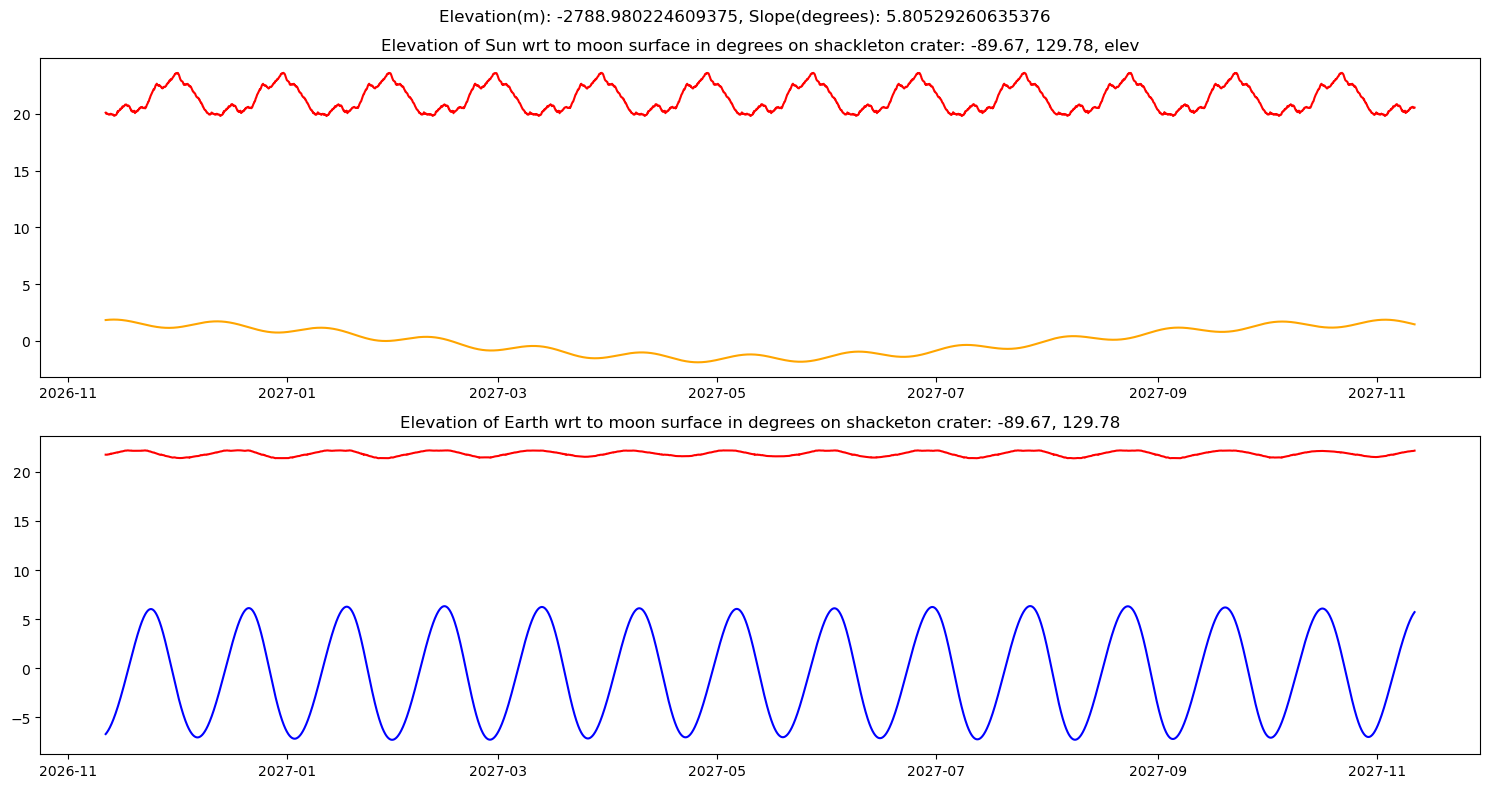

In [6]:
fig, axs = plt.subplots(2, 1, figsize = (15, 8))

fig.suptitle("Elevation(m): {}, Slope(degrees): {}".format(elev, slope))
axs[0].plot(df['datetime_utc'], df['STheta'], color='orange')
axs[0].plot(df['datetime_utc'], df['SCritTheta'], color='red', linestyle='-')
axs[0].set_title("Elevation of Sun wrt to moon surface in degrees on shackleton crater: {}, {}, elev".format(lat, long))

axs[1].plot(df['datetime_utc'], df['ETheta'], color='blue')
axs[1].plot(df['datetime_utc'], df['ECritTheta'], color='red', linestyle='-')
axs[1].set_title("Elevation of Earth wrt to moon surface in degrees on shacketon crater: {}, {}".format(lat, long))

plt.tight_layout()
plt.show()